# 移动 Web 第二天

空间转换、动画（前端第12天）


## 本日目标与资料

使用空间中的位移、旋转、缩放与关键帧动画，丰富网页元素的呈现方式。原课依次讲空间转换、动画及其案例，最后完成“全民出游”页面。

资料来自第一份分享中的 `移动Web-Day12资料.zip`，解压后根目录为 `day02/`。本篇结合25页PPT、配套Markdown与11页PDF笔记、XMind、课堂01～16源码、练习素材和配套作业整理，仍保存在 `01-HTML+CSS` 目录。

| 学习内容 | 解决的问题 | 对应案例 |
| --- | --- | --- |
| 空间转换 | 在X、Y、Z三轴上改变元素位置、角度与尺寸 | 透视效果、3D导航 |
| 关键帧动画 | 定义多个状态，并控制时长、次数、方向和暂停 | 走马灯、精灵动画、多组动画 |
| 综合应用 | 把定位、转换、背景和动画配合起来 | 全民出游季 |

`素材/` 是待补充的练习起点，`code/` 是课堂完成代码。例如走马灯素材只有7张图片，完成版增加动画及3张替身图片；全民出游素材只有页面骨架和图片，需要建立CSS并引入。以下01～15示例完整保留原文件的 `<style>` 与 `<body>`，省略重复页面头部；综合案例按真实文件展开。图片路径仍以各自源文件所在目录为基准。

补充：原Markdown标题误写“移动 Web 第一天”，综合章节误写“全名出游”；本篇依据PPT和源码使用“第二天”“全民出游”。原代码中的启用、注释状态保持原样。同一规则连续写多条 `transform` 或 `animation` 时，最后一条有效声明生效，每节会说明实际结果。


## 1. 空间转换

空间转换也叫3D转换，属性仍是 `transform`。X、Y、Z三条坐标轴构成一个立体空间；Z轴与用户视线方向重合。

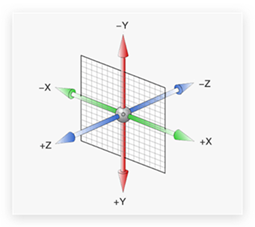

网页坐标中，X正方向向右、Y正方向向下；Z正方向指向用户，即屏幕外面，负方向指向屏幕里面。理解Z轴后，才能解释元素为什么靠近时变大、远离时变小。


### 1.1 空间平移：沿三条轴移动

| 函数 | 作用与参数 |
| --- | --- |
| `translate3d(x, y, z)` | 同时指定三轴距离，三个参数缺一不可 |
| `translateX(x)` | 沿X轴移动，正值向右 |
| `translateY(y)` | 沿Y轴移动，正值向下 |
| `translateZ(z)` | 沿Z轴移动，正值靠近用户 |

X、Y可以使用长度或百分比，百分比参照元素自身对应方向的尺寸。例如200px高的盒子 `translateY(-100%)` 向上移动200px。

补充：原课把取值概括为“与平面转换相同”，但Z距离必须使用长度，不能写百分比。`translate3d(100px, 200px)` 缺少第三个参数，是无效声明；不移动某个轴时也应明确填 `0`。

文件：`code/01-空间-平移.html`。

CSS（放在 `<style>` 内）：

```css
.box {
  width: 200px;
  height: 200px;
  margin: 100px auto;
  background-color: pink;
  transition: all 0.5s;
}

.box:hover {
  /* 电脑是平面，默认无法观察 Z 轴平移效果 */
  /* transform: translate3d(100px, 200px, 300px); */

  /* 3d 小括号里面必须逗号隔开三个数 */
  /* transform: translate3d(100px, 200px); */

  transform: translateX(100px);
  transform: translateY(-100%);
  transform: translateZ(300px);
}
```

HTML（放在 `<body>` 内）：

```html
<div class="box"></div>
```

盒子为200×200px，状态变化有0.5秒过渡。源码末尾的 `translateZ(300px)` 覆盖了前面的X、Y写法，所以它们不会自动叠加。`translate3d(100px, 200px, 300px)` 是注释中的正确组合写法，下一行是用于说明少参数的错误示例。

此文件没有添加透视，单独改变Z位置通常观察不到盒子在屏幕上的大小或二维位置变化。要比较X、Y效果，每次保留一条对应声明；要观察Z移动的远近效果，继续看下一节。


### 1.2 视距：让Z轴移动产生近大远小

`perspective` 指定观察者与 `Z=0` 平面的距离，为子元素添加透视效果。值越小，在相同Z移动距离下远近变化越明显；值越大，透视变化越弱。课堂通常取800～1200px，本例使用1000px。

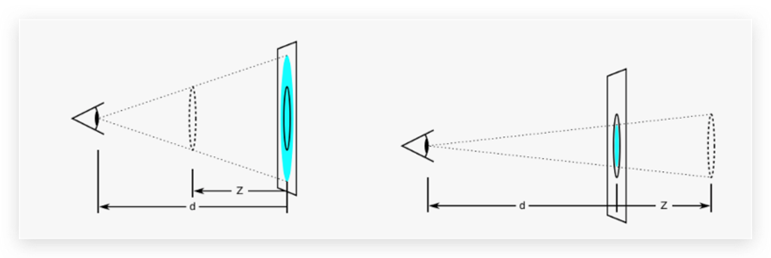

文件：`code/02-视距.html`。在 `.father` 上设置视距，再改变 `.son` 的Z位置。

CSS（放在 `<style>` 内）：

```css
/* 视距属性必须添加给 直接父级 */
.father {
  perspective: 1000px;
  /* perspective: 10000px;
  perspective: 100px; */
}

.son {
  width: 200px;
  height: 200px;
  margin: 100px auto;
  background-color: pink;
  transition: all 0.5s;
}

.son:hover{
  transform: translateZ(-300px);
  transform: translateZ(300px);
}
```

HTML（放在 `<body>` 内）：

```html
<div class="father">
  <div class="son"></div>
</div>
```

悬停时，最后的 `translateZ(300px)` 生效，子盒子向用户靠近并放大；前一条 `translateZ(-300px)` 被覆盖，单独保留它时会远离并缩小。10000px和100px的视距只是注释中的对比值。

验证时观察盒子大小变化，而不是寻找横向或纵向位移。把父级视距去掉，再比较同样的Z移动，可以看到两者的区别。

补充：源码注释要求加给“直接父级”，本例就是给直接父级 `.father` 设置；复杂结构中能否向更深后代传递透视，还与中间层的3D呈现有关。800～1200px是课堂常用范围，不是CSS合法取值的限制。课件的“近实远虚”用于描述视觉印象，`perspective` 本身不会自动给远处元素增加模糊或透明度。


### 1.3 围绕Z轴旋转

`rotateZ(角度)` 围绕垂直屏幕的轴旋转，视觉上与前一天的平面旋转相近。角度可正可负，单位使用 `deg`。

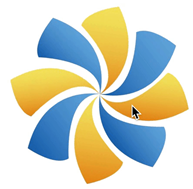

文件：`code/03-空间旋转-Z轴.html`。

CSS（放在 `<style>` 内）：

```css
.box {
  width: 300px;
  margin: 100px auto;
}

img {
  width: 300px;
  transition: all 2s;
}

.box img:hover {
  transform: rotateZ(360deg);
}
```

HTML（放在 `<body>` 内）：

```html
<div class="box">
  <img src="./images/hero.jpeg" alt="" />
</div>
```

图片显示宽300px，悬停后在2秒内旋转360deg。完整一圈的最终朝向与初始朝向一致，但过渡期间可看到旋转；移开时向初始状态过渡。原图是风车示意，课堂实际使用 `hero.jpeg`。


### 1.4 围绕X轴旋转

`rotateX(角度)` 围绕横向轴转动。为图片的父盒子添加视距，才能更明显地观察朝用户或远离用户一侧的透视差异。

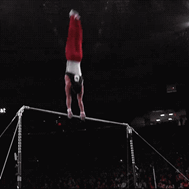

文件：`code/04-空间旋转-X轴.html`。

CSS（放在 `<style>` 内）：

```css
.box {
  width: 300px;
  margin: 100px auto;
}

img {
  width: 300px;
  transition: all 2s;
}

.box {
  /* 透视效果：近大远小，近实远虚 */
  perspective: 1000px;
}

.box img:hover {
  transform: rotateX(60deg);
  transform: rotateX(-60deg);
}
```

HTML（放在 `<body>` 内）：

```html
<div class="box">
  <img src="./images/hero.jpeg" alt="" />
</div>
```

两条 `.box` 规则共同生效：前一条设置宽度和外边距，后一条补上1000px视距。悬停规则中 `rotateX(-60deg)` 覆盖 `rotateX(60deg)`，因此直接打开时观察的是负60度。移开鼠标，图片在2秒内回到初始角度。若要比较正负方向，每次只保留一条旋转声明。


### 1.5 围绕Y轴旋转

`rotateY(角度)` 围绕纵向轴转动，呈现左右翻转过程。与X轴旋转一样，课堂把视距放在图片父级上。

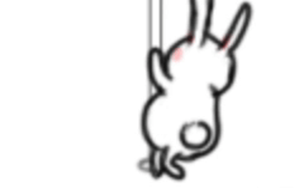

文件：`code/05-空间旋转-Y轴.html`。

CSS（放在 `<style>` 内）：

```css
.box {
  width: 300px;
  margin: 100px auto;
}

img {
  width: 300px;
  transition: all 2s;
}

.box {
  /* 透视效果：近大远小，近实远虚 */
  perspective: 1000px;
}

.box img:hover {
  transform: rotateY(60deg);
  transform: rotateY(-60deg);
}
```

HTML（放在 `<body>` 内）：

```html
<div class="box">
  <img src="./images/hero.jpeg" alt="" />
</div>
```

最后的 `rotateY(-60deg)` 生效，正60度被覆盖。对照上一节，X轴是围绕横轴转动，Y轴是围绕纵轴转动，不要把两者都记成笼统的“翻转”。


### 1.6 左手法则与自定义旋转轴

原课用左手法则判断旋转取值的正负：左手握住旋转轴，大拇指指向该轴正方向，其余四指弯曲方向就是正角度的旋转方向。先判断轴正方向，再判断旋转，避免只凭屏幕上某一侧的运动猜正负。

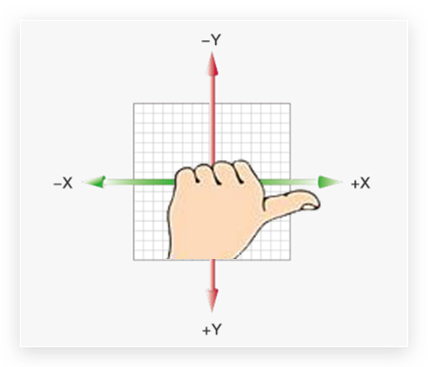

课件还介绍了 `rotate3d(x, y, z, 角度)`，用于自定义旋转轴，本日只要求了解。

补充：原资料称其为“轴的位置”，并把x、y、z限定在0～1。准确地说，这三个数表示旋转轴的**方向向量**，并不只允许0～1；浏览器会把非零向量归一化。例如 `rotate3d(1, 0, 0, 60deg)` 对应X轴旋转60度。三个分量同时为0不能定义旋转轴。


### 1.7 立体呈现：保留子元素的空间关系

`transform-style` 控制子元素是在父元素平面中呈现，还是保留3D空间位置。

| 属性值 | 效果 |
| --- | --- |
| `flat` | 默认值，子元素被压平到父元素平面中 |
| `preserve-3d` | 保留子元素的3D空间关系 |

原课的操作顺序：父元素设置 `transform-style: preserve-3d` → 子元素定位到同一基准 → 用位移或旋转调整各个面的空间位置。`perspective` 负责观察的透视，`transform-style` 负责子元素的空间呈现，两者用途不同。

文件：`code/06-立体呈现.html`。

CSS（放在 `<style>` 内）：

```css
.cube {
  position: relative;
  width: 200px;
  height: 200px;
  margin: 100px auto;
  /* background-color: pink; */
  transition: all 2s;

  transform-style: preserve-3d;

  /* 旋转与案例效果无关，用来看前后移动的效果 */
  /* transform: rotateY(89deg); */
}

.cube div {
  position: absolute;
  left: 0;
  top: 0;
  width: 200px;
  height: 200px;
}

.front {
  background-color: orange;
  transform: translateZ(100px);
}

.back {
  background-color: green;
  transform: translateZ(-100px);
}

.cube:hover {
  transform: rotateY(90deg);
}
```

HTML（放在 `<body>` 内）：

```html
<div class="cube">
  <div class="front">前面</div>
  <div class="back">后面</div>
</div>
```

`.cube` 相对定位，两个200×200px的子盒子绝对定位在相同起点：橙色前面移到 `Z=100px`，绿色后面移到 `Z=-100px`，相距200px。悬停时整个父元素在2秒内绕Y轴旋转90deg；两个面跟随父元素一起旋转。

调试用的 `rotateY(89deg)` 和父盒子的粉色背景都已注释。观察过渡中两个面的位置，可以理解为什么父级需要保留3D空间。

补充：源码只构建前后两个面，没有补齐六面，也没有设置视距。末态正好90deg时，两面从正面观察可能接近细线；不能把它描述成已经完成了六面立方体。


### 1.8 案例：3D导航

目标：默认显示绿色中文导航，鼠标移入时翻转，显示橙色英文导航。

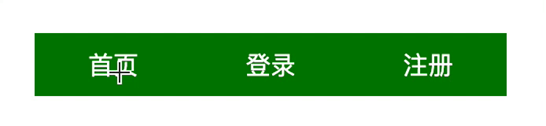

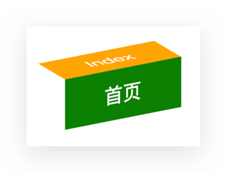

原课把导航项视作立方体的两个面：绿色是前面，橙色是上面。每项宽100px、高40px，Z方向移20px，正好是高度的一半。

1. 导航列表用Flex横排；每个 `li` 设置相对定位和 `preserve-3d`。
2. 两个链接绝对定位到同一起点，宽高填满 `li`。
3. 绿色面使用 `translateZ(20px)`；橙色面使用 `rotateX(90deg) translateZ(20px)`，形成顶面。
4. 鼠标移入 `li` 后，父级 `rotateX(-90deg)`，让橙色顶面转到正面；父级的0.5秒过渡负责翻转过程。

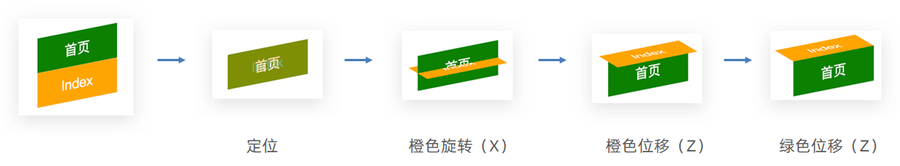

文件：`code/07-案例-3D导航.html`。

CSS（放在 `<style>` 内）：

```css
ul {
  margin: 0;
  padding: 0;
  list-style: none;
}

.nav {
  width: 300px;
  height: 40px;
  margin: 50px auto;
}

.nav ul {
  display: flex;
}

.nav li {
  position: relative;
  width: 100px;
  height: 40px;
  line-height: 40px;
  transition: all 0.5s;

  transform-style: preserve-3d;

  /* 为了看到橙色和绿色的移动过程，给立方体添加旋转 */
  /* transform: rotateX(-20deg) rotateY(30deg); */
}

.nav li a {
  position: absolute;
  left: 0;
  top: 0;
  display: block;
  width: 100%;
  height: 100%;
  text-align: center;
  text-decoration: none;
  color: #fff;
}

/* 立方体每个面都有独立的坐标轴，互不影响 */
.nav li a:first-child {
  background-color: green;
  transform: translateZ(20px);
}

.nav li a:last-child {
  background-color: orange;
  transform: rotateX(90deg) translateZ(20px);
}

.nav li:hover {
  transform: rotateX(-90deg);
}
```

HTML（放在 `<body>` 内）：

```html
<div class="nav">
  <ul>
    <li>
      <a href="#">首页</a>
      <a href="#">Index</a>
    </li>
    <li>
      <a href="#">登录</a>
      <a href="#">Login</a>
    </li>
    <li>
      <a href="#">注册</a>
      <a href="#">Register</a>
    </li>
  </ul>
</div>
```

验证时分别移入首页、登录、注册，观察当前项是否翻到Index、Login、Register，再移开恢复。链接的 `href="#"` 是演示占位，没有对应登录或注册业务。

> 每个转换元素都有自己的局部坐标轴，但父级转换也会带动子级。橙色面的函数顺序需要保持为 `rotateX(90deg) translateZ(20px)`，不能随意交换。

补充：以变换后的局部坐标理解，是先建立旋转后的坐标系，再沿该局部Z轴移动；若按矩阵对一个点的作用计算，函数列表从右向左作用。这不是动画分两段先后播放。注释中的 `rotateX(-20deg) rotateY(30deg)` 仅用于观察两个面，完成效果中未启用。案例只需要前面与上面两个面。


### 1.9 空间缩放

| 函数 | 作用 |
| --- | --- |
| `scale3d(x, y, z)` | 同时缩放三个方向，三个参数是比例 |
| `scaleX(x)` | 缩放X方向 |
| `scaleY(y)` | 缩放Y方向 |
| `scaleZ(z)` | 缩放Z方向 |

比例不带单位：1保持原比例，0～1缩小，大于1放大。Z缩放改变的是空间深度关系，单独缩放一个位于Z=0的平面元素，通常难以观察到变化；课堂沿用已构建两个面的导航观察它。

文件：`code/08-空间-缩放.html`。

CSS（放在 `<style>` 内）：

```css
ul {
  margin: 0;
  padding: 0;
  list-style: none;
}

.nav {
  width: 300px;
  height: 40px;
  margin: 50px auto;
}

.nav li {
  position: relative;
  float: left;
  width: 100px;
  height: 40px;
  line-height: 40px;
  transition: all 0.5s;
  transform-style: preserve-3d;

  transform: scaleX(0.5);
  transform: scaleY(2);
  transform: scaleZ(3);

  transform: scale3d(0.5, 2, 3);
}

.nav li a {
  position: absolute;
  left: 0;
  top: 0;
  width: 100%;
  height: 100%;
  text-align: center;
  text-decoration: none;
  color: #fff;
}

.nav li a:first-child {
  background-color: green;
  transform: translateZ(20px);
}

.nav li a:last-child {
  background-color: orange;
  transform: rotateX(90deg) translateZ(20px);
}

.nav li:hover {
  transform: rotateX(-90deg);
}
```

HTML（放在 `<body>` 内）：

```html
<div class="nav">
  <ul>
    <li>
      <a href="#">首页</a>
      <a href="#">Index</a>
    </li>
    <li>
      <a href="#">登录</a>
      <a href="#">Login</a>
    </li>
    <li>
      <a href="#">注册</a>
      <a href="#">Register</a>
    </li>
  </ul>
</div>
```

静止状态最后一条 `scale3d(0.5, 2, 3)` 生效，前三条单轴声明被覆盖：X半倍、Y两倍、Z三倍。这个文件用 `float: left` 横排，与上一份Flex导航源码不同。

悬停规则只有 `rotateX(-90deg)`，它会替换整个缩放列表，所以悬停时缩放也会向未缩放状态过渡。若要保留缩放并旋转，需要在同一 `transform` 中组合函数；这里按原源码保留。转换改变视觉形态，不把原100×40px的布局占位改成新的宽高。


## 2. 动画

前一天的 `transition` 描述两个状态之间的变化过程。本日的 `animation` 配合关键帧定义两个或多个状态，还能控制重复播放、播放方向、结束后状态和暂停。


### 2.1 先体验自动往返的动画

文件：`code/09-动画-体验.html`。

CSS（放在 `<style>` 内）：

```css
div {
  width: 100px;
  height: 100px;
  background-color: pink;

  animation: change 1s infinite alternate;
}

@keyframes change {
  0% {
    transform: translate(0);
  }

  100% {
    transform: translate(600px);
  }
}
```

HTML（放在 `<body>` 内）：

```html
<div></div>
```

100×100px粉色盒子无需鼠标触发，页面加载后就从初始位置移动到右侧600px处。`1s` 是单次播放时长，`infinite` 无限重复，`alternate` 让相邻轮次交替方向：第一轮从0到600px，第二轮从600px回到0，再持续往返。

补充：此处未写速度曲线，使用默认 `ease`；不能把它描述成匀速。`alternate` 是交替正向和反向，不是每一轮都反向。


### 2.2 动画实现步骤：定义，再使用

先用 `@keyframes` 定义动画及每个状态，再给目标元素设置 `animation`。`from`、`to` 分别对应0%、100%；百分比写法适合描述多个关键状态。

文件：`code/10-动画实现步骤.html`。

CSS（放在 `<style>` 内）：

```css
.box {
  width: 200px;
  height: 100px;
  background-color: pink;

  animation: change 1s;
}

/* 动画一：宽度从200变化到800 */
/* @keyframes change {
  from {
      width: 200px;
  }
  to {
      width: 800px;
  }
} */


/* 动画二：从 200*100 变化到 300*300 变化到800*500 */
/* 百分比：表示的意思是动画时长的百分比 */
@keyframes change {
  0% {
      width: 200px;
      height: 100px;
  }
  20% {
      width: 300px;
      height: 300px;
  }
  100% {
      width: 800px;
      height: 500px;
  }
}
```

HTML（放在 `<body>` 内）：

```html
<div class="box"></div>
```

源码中第一套 `from/to` 只改变宽度，整段已注释。实际启用的是第二套百分比关键帧，并通过 `.box` 的 `animation: change 1s` 使用。

| 关键帧 | 单次1秒动画中的时刻 | 盒子尺寸 |
| --- | --- | --- |
| `0%` | 开始，0秒 | 200×100px |
| `20%` | 0.2秒 | 300×300px |
| `100%` | 1秒 | 800×500px |

百分比表示**动画时长的百分比**，不是元素宽高的百分比。关键帧之间由浏览器按速度曲线计算中间状态。

直接打开时播放一次，结束后没有保留样式的设置，回到基础样式的200×100px。若动画太快，重新加载页面观察；不能把结束后的基础尺寸误判成关键帧未生效。

补充：原课要求动画名称和时长必须赋值，是为了得到有持续时间的可见效果。`animation-name` 默认 `none`，`animation-duration` 默认 `0s`，只定义关键帧而没有给元素使用，也不会自动播放。


### 2.3 animation复合属性

课堂推荐把名称、时长及播放控制写在一条声明中：

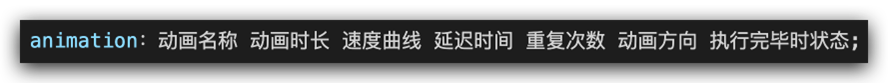

各类取值通常可调整顺序，但要能明确区分；如果出现两个时间，第一个一定是动画时长，第二个是延迟时间。多个动画要用逗号分隔，后面单独学习。

文件：`code/11-animation复合属性.html`。

CSS（放在 `<style>` 内）：

```css
.box {
  width: 200px;
  height: 100px;
  background-color: pink;

  /* linear：匀速 */
  animation: change 1s linear;

  /* steps：分步动画，工作中，配合精灵图实现精灵动画 */
  animation: change 1s steps(3);

  /* 如果有两个时间，第一个是动画时长，第二个是延迟时间 */
  animation: change 1s 2s;

  /* 重复次数，infinite：无限循环 */
  animation: change 1s 3;
  animation: change 1s infinite;

  /* alternate：反向 */
  animation: change 1s infinite alternate;

  /* 动画执行完毕时的状态， forwards：结束状态； backwards：开始状态（默认） */
  animation: change 1s forwards;
  animation: change 1s backwards;
}

/* 宽度 从 200 变化到 800 */
@keyframes change {
  from {
      width: 200px;
  }
  to {
      width: 800px;
  }
}
```

HTML（放在 `<body>` 内）：

```html
<div class="box"></div>
```

这份文件把不同写法连续放在同一规则中供比较，**直接打开时仅最后的 `animation: change 1s backwards` 生效**。观察其他写法时，每次只保留对应的一条声明。

| 写法中的取值 | 单独使用该声明时的行为 |
| --- | --- |
| `linear` | 按匀速曲线把宽度从200px变到800px |
| `steps(3)` | 以3个跳变步骤改变宽度 |
| `1s 2s` | 等待2秒后播放，播放时长1秒 |
| `3` | 播放3次；未设填充时，结束回基础宽度 |
| `infinite` | 无限重复，每次正向从200px到800px |
| `infinite alternate` | 无限往返，200→800，再800→200 |
| `forwards` | 播放一次后保持结束关键帧的800px宽 |
| `backwards` | 在延迟阶段应用起始关键帧，播放结束后仍回基础样式 |

补充：原源码注释把 `backwards` 写成“开始状态（默认）”，课件表也将其列作结束时的第一帧状态，这两处不准确。`animation-fill-mode` 默认是 `none`；`backwards` 主要决定延迟等待阶段使用起始关键帧，不能用来保持结束后的第一帧。当前最后一条没有延迟，且基础宽度与第一帧都是200px，播放结束回到200px，因此不易看出 `backwards` 的意义。


### 2.4 拆分写法与暂停

拆分写法适合单独调整一个控制项。下面保留原课属性表，`fill-mode` 和 `alternate` 的含义按上一节补充理解。

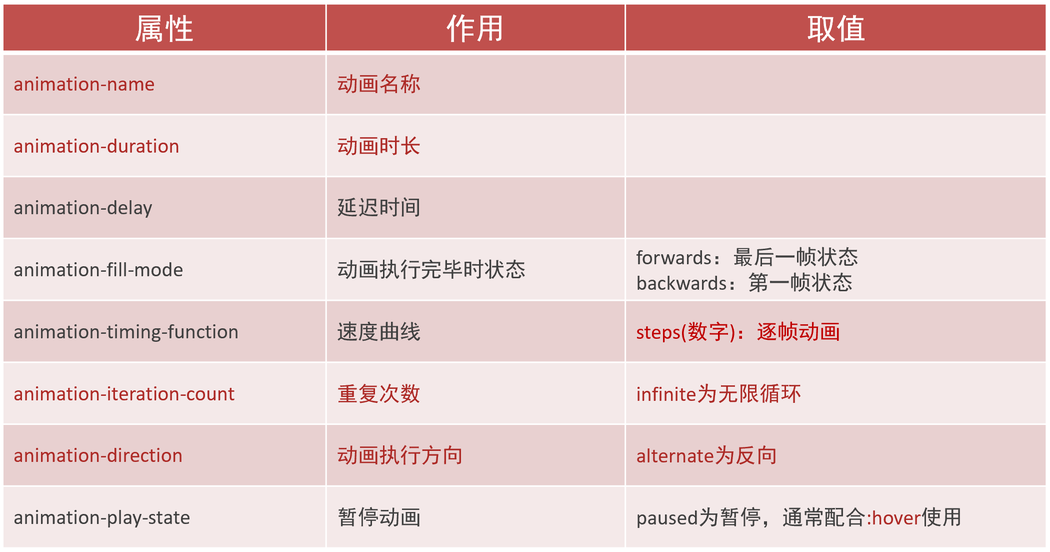

| 属性 | 作用 | 本日使用的取值或默认值 |
| --- | --- | --- |
| `animation-name` | 指向 `@keyframes` 名称 | `change`；默认 `none` |
| `animation-duration` | 单次播放时长 | `1s`；默认 `0s` |
| `animation-delay` | 开始前延迟 | `2s` 等；默认 `0s` |
| `animation-fill-mode` | 动画活动区间之外应用哪种关键帧样式 | 默认 `none`；`forwards` 保留结束状态，`backwards` 用于延迟阶段 |
| `animation-timing-function` | 速度曲线 | 默认 `ease`；`linear` 匀速，`steps(N)` 分步 |
| `animation-iteration-count` | 播放次数 | 默认 `1`；`infinite` 无限重复 |
| `animation-direction` | 迭代方向 | 默认 `normal`；`alternate` 交替方向 |
| `animation-play-state` | 运行或暂停 | 默认 `running`；`paused` 暂停 |

文件：`code/12-animation拆分写法.html`。

CSS（放在 `<style>` 内）：

```css
.box {
  width: 200px;
  height: 100px;
  background-color: pink;

  /* 动画名称 */
  animation-name: change;
  /* 动画时长 */
  animation-duration: 1s;
  /* 播放次数 */
  animation-iteration-count: infinite;

  /* animation-play-state: paused; */
}

.box:hover {
  /* 暂停动画 */
  animation-play-state: paused;
}


/* 宽度从 200 变化到 800 */
@keyframes change {
  0% {
      width: 200px;
  }
  100% {
      width: 800px;
  }
}
```

HTML（放在 `<body>` 内）：

```html
<div class="box"></div>
```

宽度在200px与800px之间每秒正向播放一次，无限重复。鼠标移入 `.box` 时，`animation-play-state: paused` 将动画停在当前进度；移开后悬停规则失效，恢复 `running`，从暂停处继续播放。

验证时先观察宽度变化，再移入正在变化的盒子，看宽度是否停止；移开后应续播，不是每次从200px重新启动。基础规则中的暂停声明只是注释，没有让动画默认暂停。


### 2.5 案例：无缝走马灯

目标：图片列表匀速向左滚动，鼠标移入可暂停，重复播放时不露白。

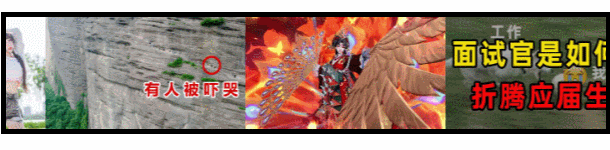

1. 显示窗口设置600×112px，用 `overflow: hidden` 隐藏窗口外的内容。
2. 图片显示宽200px，列表用Flex横排；图片设为块级，去掉行内图片的基线留白。
3. 给 `ul` 添加6秒匀速、无限循环的位移动画。
4. 将开头3张图片再复制到结尾，填满600px窗口；鼠标移入窗口时暂停列表动画。

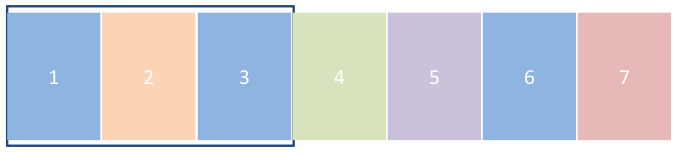

文件：`code/13-案例-走马灯/走马灯.html`，图片在同级 `images/`。

CSS（放在 `<style>` 内）：

```css
* {
  padding: 0;
  margin: 0;
}
li {
  list-style: none;
}

img {
  display: block;
  width: 200px;
}

.box {
  width: 600px;
  height: 112px;
  border: 5px solid #000;
  margin: 100px auto;
  overflow: hidden;
}

.box ul {
  display: flex;
  animation: move 6s infinite linear;
}

/* 定义位移动画；ul使用动画；鼠标悬停暂停动画 */
@keyframes move {
  0% {
    transform: translate(0);
  }
  100% {
    transform: translate(-1400px);
  }
}

.box:hover ul {
  animation-play-state: paused;
}
```

HTML（放在 `<body>` 内）：

```html
<div class="box">
  <ul>
    <li><img src="./images/1.jpg" alt="" /></li>
    <li><img src="./images/2.jpg" alt="" /></li>
    <li><img src="./images/3.jpg" alt="" /></li>
    <li><img src="./images/4.jpg" alt="" /></li>
    <li><img src="./images/5.jpg" alt="" /></li>
    <li><img src="./images/6.jpg" alt="" /></li>
    <li><img src="./images/7.jpg" alt="" /></li>
    <!-- 替身：填补显示区域的露白 -->
    <li><img src="./images/1.jpg" alt="" /></li>
    <li><img src="./images/2.jpg" alt="" /></li>
    <li><img src="./images/3.jpg" alt="" /></li>
  </ul>
</div>
```

这里有7张原图，原始序列长度为 `7 × 200 = 1400px`。窗口宽600px，一次显示3张，所以替身为 `1、2、3`，合计 `3 × 200 = 600px`。列表最终有10项，内容总长2000px，但动画移动距离仍是**原始序列的1400px**。

移动到 `-1400px` 时，窗口正好看到结尾复制的1、2、3；下一轮瞬间回到 `0` 时，看到的是开头的1、2、3。两个画面相同，所以视觉上无缝。如果不复制，列表末尾进入窗口后会留下空白。

补充：源码没有 `box-sizing: border-box`，600px是内容窗口宽，连同两侧5px边框，盒子外宽610px；替身宽度按600px计算。源码没有给 `li` 显式宽度，本例图片设为200px，且列表项默认的最小内容约束使每项保留图片宽度。不要把所有Flex布局都概括为自动固定200px。

验证：观察6秒处是否顺畅回到开头；移入黑框区域时列表停止，移开从当前进度继续。复制的替身必须保持原开头顺序。


### 2.6 精灵动画：steps与CSS精灵图配合

普通补间动画连续计算中间状态；逐帧动画按离散步骤跳变。精灵动画把一系列动作图放在同一张精灵图中，窗口一次只显示一帧，配合 `steps(N)` 跳变背景位置，形成连续动作。

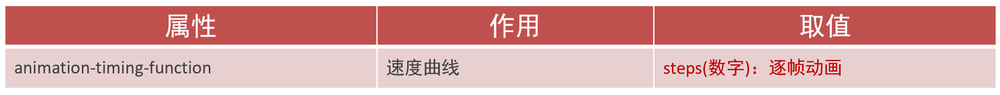

本例的 `code/images/bg.png` 实际为1680×140px，横向排列12帧。每帧宽 `1680 ÷ 12 = 140px`，高140px。

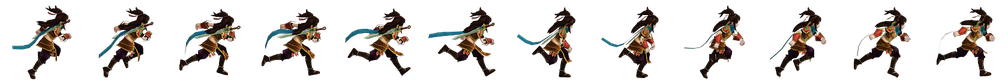

制作顺序：显示区域设为140×140px → 将精灵图设为背景 → 背景从 `0 0` 移到 `-1680px 0` → 使用 `steps(12)`，每秒重复一轮。

文件：`code/14-精灵动画.html`。

CSS（放在 `<style>` 内）：

```css
div {
  width: 140px;
  height: 140px;
  border: 1px solid #000;
  background-image: url(./images/bg.png);
  animation: run 1s steps(12) infinite;
}

@keyframes run {
  from {
    background-position: 0 0;
  }
  to {
    background-position: -1680px 0;
  }
}
```

HTML（放在 `<body>` 内）：

```html
<div></div>
```

盒子本身不移动，变化的是 `background-position`。横向背景每次跳140px：第1帧对应0，第2帧对应-140px，依次到第12帧对应-1540px；一轮关键帧终点写的是整张图宽度的负值-1680px。

补充：`steps(12)` 默认在每段结束时跳变，即 `steps(12, end)`。0到-1680px被切成12段，最后一段显示第12帧，下一轮回到起点。原文件也没有关闭背景重复，完整图宽度的周期位移与回到首帧吻合；不能把终点直接改成-1540px，否则12步的每步距离不再是140px。预览图为阅读缩小，课堂计算仍用原始1680×140px尺寸。

验证时应看到人物原地循环做动作，而不是整张图平滑滑过窗口。黑色1px边框用于观察显示区域；在默认盒模型下外尺寸为142×142px，背景帧的内容区域仍为140×140px。


### 2.7 多组动画：动作与移动同时发生

同一元素要同时使用多个动画，应写在一条 `animation` 声明中，各组用逗号分隔。不能写多条同名声明期待它们叠加。

文件：`code/15-多组动画.html`。

CSS（放在 `<style>` 内）：

```css
div {
  width: 140px;
  height: 140px;
  /* border: 1px solid #000; */
  background-image: url(./images/bg.png);
  animation: 
    run 1s steps(12) infinite,
    move 3s forwards
  ;
}

/* 当动画的开始状态样式 跟 盒子默认样式相同，可以省略动画开始状态的代码 */
@keyframes run {
  /* from {
    background-position: 0 0;
  } */
  to {
    background-position: -1680px 0;
  }
}

@keyframes move {
  /* 0% {
    transform: translate(0);
  } */
  100% {
    transform: translate(800px);
  }
}
```

HTML（放在 `<body>` 内）：

```html
<div></div>
```

| 动画 | 改变的属性 | 播放方式 |
| --- | --- | --- |
| `run` | `background-position` | 1秒、12步、无限重复 |
| `move` | `transform` | 3秒、播放一次、结束后保持右移800px |

两个动画修改不同属性，因此可同时呈现“人物做动作”和“人物向右移动”。3秒后 `move` 结束，`forwards` 保持右移800px，`run` 仍循环播放。

本文件把开始关键帧注释了：背景默认起点是 `0 0`，元素默认没有位移，可由基础样式补齐缺失起点。省略起点要以目标元素的实际基础样式为依据，不是所有动画都能任意省略。

补充：PPT第23页写的是 `move 3s linear forwards`，课堂HTML实际是 `move 3s forwards`，使用默认 `ease`，移动并非匀速。这里保留源码差异；要验证PPT的匀速效果，可在同一组内补上 `linear`。两组动画同时开始，不是先完成 `run` 再执行 `move`。


## 3. 综合案例：全民出游季

把背景、绝对定位、关键帧缩放与循环位移组合成宣传页面。

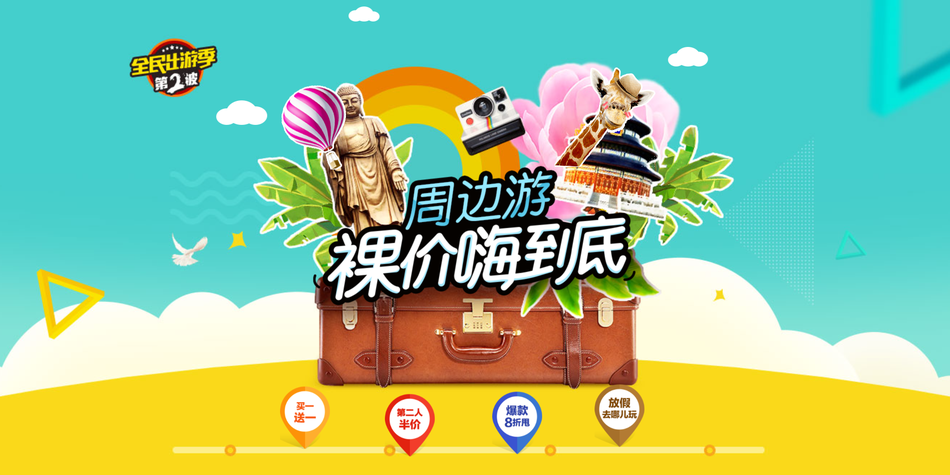

资料包含三个阶段：`素材/16-全民出游季/` 是空页面与图片；`code/16-全民出游季/` 是课堂完成版，包含背景、三朵云、中央文字；`code/全民出游季-完整版/` 和 `作业/全民出游季/` 的HTML与图片完全相同，另含热气球、长颈鹿和底部四张跳动文字图片。先按课堂版学习，再对照完整版。


### 3.1 建立课堂版HTML与CSS文件

在 `code/16-全民出游季/` 中，HTML引入 `./css/index.css`，云和文字图片从 `./images/` 读取。

文件：`code/16-全民出游季/全民出游.html`。

```html
<!DOCTYPE html>
<html lang="en">
<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>全民出游季</title>
  <link rel="stylesheet" href="./css/index.css">
</head>
<body>
  <!-- 云 -->
  <div class="cloud">
    <img src="./images/yun1.png" alt="">
    <img src="./images/yun2.png" alt="">
    <img src="./images/yun3.png" alt="">
  </div>

  <!-- 文字 -->
  <div class="text">
    <img src="./images/font1.png" alt="">
  </div>
</body>
</html>
```

`.cloud` 中的三张图用 `nth-child` 分别定位和控制延迟；`.text` 中使用已含文字与装饰的 `font1.png`。这一版不包含单独的热气球、长颈鹿和底部文字节点。

下面3.2～3.4按原文件顺序连续保留 `css/index.css` 的全部样式。CSS中的背景路径以CSS文件为基准，因此是 `../images/f1_1.jpg`。


### 3.2 背景：先建立视口高度基准

文件：`code/16-全民出游季/css/index.css`，起始部分。

```css
* {
  margin: 0;
  padding: 0;
}

/* 大背景 */
/* 默认状态HTML和body的高度是0，所以导致cover缩放背景图不成功 */
html {
  height: 100%;
}
body {
  height: 100%;
  background: url(../images/f1_1.jpg) no-repeat center 0 / cover;
  /* background-size: cover; */
}
```

先清除默认内外边距，再让 `html`、`body` 都取100%高度。`no-repeat` 防止平铺，`center 0` 表示水平居中、顶部对齐，`cover` 等比缩放背景，覆盖整个容器，可能裁掉超出边缘的部分。

验证时背景应覆盖浏览器可视高度，调整窗口尺寸后仍铺满，图片比例保持不变。

补充：原注释“默认状态HTML和body的高度是0”是针对案例现象的简化说法。默认高度是 `auto`，会受普通流内容影响；本例主要内容绝对定位，不撑开父级高度，所以需要显式建立高度基准。设置100%并不是所有网页的固定起手式。


### 3.3 云彩：居中基准、分开位置、错开开始时间

继续写同一 `css/index.css`。

```css
/* 云 */
.cloud img {
  position: absolute;
  left: 50%;
}

.cloud img:nth-child(1) {
  margin-left: -250px;
  top: 20px;
  animation: cloud 1s infinite alternate linear;
}
.cloud img:nth-child(2) {
  margin-left: 400px;
  top: 100px;
  animation: cloud 1s infinite alternate linear 0.4s;
}
.cloud img:nth-child(3) {
  margin-left: -550px;
  top: 200px;
  animation: cloud 1s infinite alternate linear 0.6s;
}

@keyframes cloud {
  100% {
    transform: translate(20px);
  }
}
```

三张云图都绝对定位，先用 `left: 50%` 把左边缘放到水平方向中点，再通过 `margin-left` 分别偏移。课堂版没有定位祖先，这些绝对定位元素以初始包含块为基准。

| 云图 | 水平偏移 | 顶部位置 | 播放延迟 |
| --- | --- | --- | --- |
| `yun1.png` | -250px | 20px | 0秒 |
| `yun2.png` | 400px | 100px | 0.4秒 |
| `yun3.png` | -550px | 200px | 0.6秒 |

三张图使用同一 `cloud` 动画，1秒内水平右移20px，以 `linear` 匀速执行，再通过 `alternate` 反向返回，持续往返。这里只写100%终点，0%由基础状态补齐。不同延迟让云彩不在同一时刻出发。

验证时观察三朵云是否分别位于指定区域，且错开开始往返；它们的动画时长都是1秒，0.4s和0.6s是延迟，不是播放时长。


### 3.4 中央文字：缩放时保留居中位移

继续写同一 `css/index.css` 的末尾部分。

```css
/* 文字 */
.text img {
  position: absolute;
  left: 50%;
  top: 50%;
  transform: translate(-50%, -50%);
  animation: text 1s;
}

/* 默认 → 小 → 大 → 小 → 默认 */
@keyframes text {
  0% {
    transform: translate(-50%, -50%) scale(1);
  }
  20% {
    transform: translate(-50%, -50%) scale(0.1);
  }
  40% {
    transform: translate(-50%, -50%) scale(1.4);
  }
  70% {
    transform: translate(-50%, -50%) scale(0.8);
  }
  100% {
    transform: translate(-50%, -50%) scale(1);
  }
}
```

图片先用 `left: 50%; top: 50%` 定位，再用 `translate(-50%, -50%)` 向自身宽高的一半反向移动，完成居中。前者参照包含块，后者参照图片自身。

| 关键帧 | 缩放比例 | 视觉过程 |
| --- | --- | --- |
| `0%` | 1 | 默认大小 |
| `20%` | 0.1 | 缩得很小 |
| `40%` | 1.4 | 放大超过默认 |
| `70%` | 0.8 | 再次缩小 |
| `100%` | 1 | 恢复默认 |

> 每个关键帧都必须保留 `translate(-50%, -50%)`。只写 `scale(...)` 会替换该时刻整个 `transform`，丢失居中位移，导致文字偏离中央。

加载页面后播放一次1秒缩放。课堂版没有 `forwards`，结束回到基础样式；基础样式与最终关键帧的视觉状态一致，所以文字仍居中且保持默认大小。刷新可再次观察，不需要悬停触发。


### 3.5 完整版与作业：补齐页面结构

对应文件：`code/全民出游季-完整版/全民出游.html`，或内容完全相同的 `作业/全民出游季/全民出游.html`。这一版样式直接写在HTML的 `<style type="text/css">` 中，图片和背景路径都以HTML所在目录为基准，不能沿用上一版CSS文件的 `../images/`。

完整 `<body>`：

```html
<div class="box">
  <!-- 白云 -->
  <div class="cloud">
    <img src="images/yun1.png" />
    <img src="images/yun2.png" />
    <img src="images/yun3.png" />
  </div>

  <!-- 热气球 -->
  <div class="balloon">
    <img src="images/san.png" />
  </div>

  <!-- 长颈鹿 -->
  <div class="giraffe">
    <img src="images/lu.png" />
  </div>

  <!-- 文字 -->
  <div class="text">
    <img src="images/font1.png" />
  </div>

  <!-- 跳动文字 -->
  <div class="jump_text">
    <img src="images/1.png" />
    <img src="images/2.png" />
    <img src="images/3.png" />
    <img src="images/4.png" />
  </div>
</div>
```

外层 `.box` 承载背景并作为定位基准，内部依次是云彩、热气球、长颈鹿、中央文字和底部四张图片。`san.png`、`lu.png`、`1.png`～`4.png` 都是资料中的现成图片。

下面两节按原 `<style>` 的顺序保留所有CSS。复制学习时将两段放回同一个 `<style type="text/css">`，不要把两种版本的选择器混用：课堂版动画施加在 `.text img`，完整版施加在 `.text` 容器。


### 3.6 完整版的布局与动画绑定

同一HTML的 `<style>` 起始部分，直到关键帧定义之前。

```css
* {
  margin: 0;
  padding: 0;
}

html,
body {
  width: 100%;
  height: 100%;
}

.box {
  width: 100%;
  height: 100%;
  background: url('images/f1_1.jpg') no-repeat top center;
  background-size: cover;
  position: relative;
}

.cloud img {
  position: absolute;
  left: 50%;
}

.cloud img:nth-child(1) {
  top: 20px;
  margin-left: -260px;
  animation: cloud 2s linear infinite alternate;
}

.cloud img:nth-child(2) {
  top: 100px;
  margin-left: 380px;
  animation: cloud 2.5s linear infinite alternate;
}

.cloud img:nth-child(3) {
  top: 200px;
  margin-left: -560px;
  animation: cloud 3s linear infinite alternate;
}

.balloon {
  position: absolute;
  left: 50%;
  top: 20%;
  margin-left: -390px;
  animation: balloon 1.5s linear alternate infinite;
}

.giraffe {
  position: absolute;
  left: 50%;
  margin-left: 160px;
  top: 15%;
}

.text {
  position: absolute;
  left: 50%;
  top: 50%;
  transform: translate(-50%, -50%);
  animation: text 1s ease forwards;
}

.jump_text img {
  position: absolute;
  left: 50%;
  bottom: 42px;
  width: 100px;
}

.jump_text img:nth-child(1) {
  margin-left: -390px;
  animation: jump_text 0.8s infinite alternate;
}

.jump_text img:nth-child(2) {
  margin-left: -180px;
  animation: jump_text 0.8s 0.2s infinite alternate;
}

.jump_text img:nth-child(3) {
  margin-left: 35px;
  animation: jump_text 0.8s 0.4s infinite alternate;
}

.jump_text img:nth-child(4) {
  margin-left: 240px;
  animation: jump_text 0.8s 0.6s infinite alternate;
}
```

完整版给 `.box` 设置 `position: relative` 和满宽满高，使内部绝对定位以它为基准。整体仍用“50%中点＋偏移”安排位置，但数值与课堂版不同。

| 元素 | 定位与播放设置 |
| --- | --- |
| 三朵云 | 水平偏移-260、380、-560px；顶部20、100、200px；时长2、2.5、3秒，匀速往返，无额外延迟 |
| 热气球 `.balloon` | `left: 50%`、`top: 20%`、偏移-390px；1.5秒匀速往返 |
| 长颈鹿 `.giraffe` | `left: 50%`、`top: 15%`、偏移160px；源码只定位，没有绑定动画 |
| 中央文字 `.text` | 水平垂直居中；`text 1s ease forwards` |
| 底部四张图 | 宽100px，距底部42px；水平偏移-390、-180、35、240px |

底部四图都使用0.8秒的 `jump_text` 动画，延迟依次为0、0.2、0.4、0.6秒，通过错开起跳形成节奏。原代码没有给这四组写 `linear`，采用默认 `ease`。

这里的三朵云是通过**不同动画时长**形成不同节奏，课堂版则用相同时长、不同延迟。不要把两组参数当成同一份最终代码。


### 3.7 完整版的关键帧与检查

同一 `<style>` 的剩余部分。

```css
/* 白云动画 */
@keyframes cloud {
  0% {
    transform: translateX(0px);
  }

  100% {
    transform: translateX(40px);
  }
}

/* 热气球动画 */
@keyframes balloon {
  0% {
    transform: translateY(0px);
  }

  100% {
    transform: translateY(-30px);
  }
}

/* 跳动文字 */
@keyframes jump_text {
  0% {
    transform: translateY(0px);
  }

  100% {
    transform: translateY(-30px);
  }
}

/* 文字 */
/* 注意：因为transform是复合属性，所以我们要重新申明一遍translate */
@keyframes text {
  0% {
    transform: translate(-50%, -50%) scale(1);
  }
  20% {
    transform: translate(-50%, -50%) scale(0);
  }

  40% {
    transform: translate(-50%, -50%) scale(1.4);
  }

  70% {
    transform: translate(-50%, -50%) scale(0.8);
  }

  100% {
    transform: translate(-50%, -50%) scale(1);
  }
}
```

| 动画 | 关键帧变化 | 最终行为 |
| --- | --- | --- |
| `cloud` | `translateX(0px)` → `translateX(40px)` | 与各云的2、2.5、3秒时长配合，持续往返 |
| `balloon` | `translateY(0px)` → `translateY(-30px)` | 热气球上下浮动 |
| `jump_text` | `translateY(0px)` → `translateY(-30px)` | 四张底部图错开起跳，持续往返 |
| `text` | 缩放1 → 0 → 1.4 → 0.8 → 1，并始终保留居中位移 | 1秒后保持最终状态 |

完整版与课堂版的中央文字20%帧也不同：完整版是 `scale(0)`，会缩到不可见；课堂版是 `scale(0.1)`，还保留十分之一大小。完整版使用 `forwards`，课堂版未设置。两者最终都回到视觉上的默认大小，但代码状态应分清。

对照资料检查页面：

1. 背景覆盖容器，云、热气球、长颈鹿、中央文字及四张底部图片均能显示，图片路径没有错位。
2. 中央文字缩放时始终居中，播放一次后稳定；刷新可再观察。
3. 云持续水平往返；热气球与底部图片持续上下往返，底部四图起跳时间错开。
4. 长颈鹿仅静态摆放，原源码没有长颈鹿动画；页面也没有JavaScript或底部按钮跳转逻辑。

课堂版、完整版和作业都使用本日已经讲过的定位、转换、背景与关键帧动画。练习时按对应版本的文件结构和参数还原，重点检查动画究竟绑定在容器还是图片，以及关键帧是否覆盖了原来的 `transform`。
